# Metaheuristics for Multi-Resource Workload Allocation
### Hardware-constrained AI model selection (0-1 multidimensional knapsack)

**Student ID:** 30068136  **Module:** Artificial Intelligence, coursework (100 marks)

| Section | Content | Instance |
|---|---|---|
| 0 | Setup: data loading, exact optimum (answer key for evaluating), shadow prices, correctness checks | both |
| 1 | Shared solver library: evaluator, constraint handlers, operators, hill climber + GA, statistics | both |
| **Part 1** | Baseline hill climber, and a test of three constraint-handling strategies | n=28, m=2 |
| **Part 2** | Steady-state genetic algorithm with greedy repair | n=90, m=5 |
| **Part 3** | Controlled experiment (H1): repair vs penalty, 30 runs each, Mann–Whitney U + A12, quality / constraint / time trade-off | n=90, m=5 |
| 4 | Additional experiments beyond the brief: which repair weights work best (H2), and when the population helps | n=90, m=5 |
| 5 | Conclusions, limitations, references | both |

**Reproducibility.** `numpy.random.seed(42)` is set globally, and every run *k* uses its own random generator `np.random.default_rng(42 + k)`. All numbers below can be regenerated with *Kernel → Restart & Run All*. Only `numpy`, `scipy`, `pandas` and `matplotlib` are used. All search logic is written from scratch.

## 0. Setup and data loading

In [1]:
import time, itertools
from pathlib import Path
from dataclasses import dataclass, field
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds   # exact solver: answer key only (see §0.1)
from scipy.stats import mannwhitneyu, spearmanr             # statistical tests
from workload_data_loader import load_workload_instance     # helper provided with the assignment

MASTER_SEED = 42
np.random.seed(MASTER_SEED)   # global seed; each run also gets its own generator
N_RUNS = 30                   # number of independent runs per experiment (M >= 30)
pd.set_option("display.precision", 2)

# Plot style: three colour-blind-safe colours, thin lines, light grid
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "ink": "#0b0b0b", "muted": "#52514e"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#9a9993", "axes.labelcolor": C["ink"], "xtick.color": C["muted"],
    "ytick.color": C["muted"], "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

In [2]:
@dataclass
class Instance:
    """One problem instance (utilities, resource use, capacities) plus the values computed in Section 0."""
    name: str
    n: int                     # number of candidate models
    m: int                     # number of resources
    p: np.ndarray              # utility of each model, shape (n,)
    R: np.ndarray              # resource use: R[i, j] = amount of resource i used by model j, shape (m, n)
    b: np.ndarray              # capacity of each resource, shape (m,)
    optimum: float = None      # true best utility (exact solver, §0.1) - used ONLY for scoring
    bound: float = None        # Lagrangian upper bound (own code, §0.2) - for information
    duals: np.ndarray = None   # shadow price of each resource (own code, §0.2) - used by the repair

def load(path, name):
    """Load an instance file with the provided helper, sanity-check it, and return an Instance."""
    n, m, p, R, b = load_workload_instance(path)
    assert p.shape == (n,) and R.shape == (m, n) and b.shape == (m,)     # shapes match n and m
    assert (R >= 0).all() and (p > 0).all()                              # no negative values
    assert (R <= b[:, None]).all(), "every single model fits on its own"
    return Instance(name, n, m, p, R, b)

def find_data_file(*names, folders=(".", "data")):
    """Return the path of the first matching data file, looking next to the notebook and in ./data.

    Several names can be given because Canvas downloads sometimes add " (1)" to the file name.
    Raises FileNotFoundError if none is found.
    """
    for folder in folders:
        for name in names:
            path = Path(folder) / name
            if path.exists():
                return str(path)
    raise FileNotFoundError(f"Cannot find {names[0]}. Place it in the same folder as this notebook.")

I1 = load(find_data_file("multi_resource_n28_m2.txt"), "Instance 1 (n=28, m=2)")
I2 = load(find_data_file("multi_resource_n90_m5.txt", "multi_resource_n90_m5 (1).txt"), "Instance 2 (n=90, m=5)")
print("loaded:", find_data_file("multi_resource_n28_m2.txt"), "|",
      find_data_file("multi_resource_n90_m5.txt", "multi_resource_n90_m5 (1).txt"))

# Overview table. "tightness" = capacity / total demand of all models (lower = scarcer resource)
pd.DataFrame([{
    "Instance": I.name, "Models (n)": I.n, "Resources (m)": I.m, "Search space": f"2^{I.n} = {2.0**I.n:.2e}",
    "Capacities": I.b.astype(int).tolist(),
    "Tightness (capacity ÷ total demand)": np.round(I.b / I.R.sum(1), 2).tolist(),
} for I in (I1, I2)]).set_index("Instance")

loaded: multi_resource_n28_m2.txt | multi_resource_n90_m5 (1).txt


,Models (n),Resources (m),Search space,Capacities,Tightness (capacity ÷ total demand)
Instance,,,,,
"Instance 1 (n=28, m=2)",28,2,2^28 = 2.68e+08,"[500, 500]","[0.44, 0.5]"
"Instance 2 (n=90, m=5)",90,5,2^90 = 1.24e+27,"[2100, 1100, 3300, 3700, 3600]","[0.63, 0.33, 0.85, 0.95, 0.91]"


**Tightness** is a resource's capacity divided by the total amount all models together would need. On Instance 2, resource 2 can only cover a third of the total demand (0.33), while resources 4 and 5 could cover almost all of it (0.95, 0.91). This is a first hint that resource 2 is the bottleneck, which §0.2 confirms.

### 0.1 Reference optimum (answer key for scoring)
The instances are small enough for an exact algorithm (branch and bound, via SciPy's mixed-integer solver `scipy.optimize.milp`) to find the **true best selection**, i.e. the global optimum. It is used **only** to score results: the optimality gap, $100\,(f^*-f)/f^*$ (how far a run falls short of the best, in %), and the success rate (how many runs reach it).

In [3]:
def solve_reference(I):
    """Find the exact optimum with SciPy's MILP solver, store it in I.optimum and return the 0/1 vector.

    Used ONLY as the answer key for scoring the algorithms; no algorithm ever calls it.
    """
    # milp minimises, so we pass -p to maximise utility; integrality=1 forces every x_j to be 0 or 1.
    res = milp(-I.p, constraints=LinearConstraint(I.R, -np.inf, I.b),
               integrality=np.ones(I.n), bounds=Bounds(0, 1))
    x_opt = np.round(res.x).astype(int)
    assert (I.R @ x_opt <= I.b).all()              # double-check the answer respects every limit
    I.optimum = float(I.p @ x_opt)                 # compute the value from the 0/1 vector (avoids float noise)
    return x_opt

for I in (I1, I2):
    x_opt = solve_reference(I)
    print(f"{I.name}: optimum f* = {I.optimum:,.0f}  ({x_opt.sum()} models)\n"
          f"   resource use at optimum = {(I.R @ x_opt).astype(int)}  vs b = {I.b.astype(int)}")

Instance 1 (n=28, m=2): optimum f* = 130,883  (11 models)
   resource use at optimum = [495 499]  vs b = [500 500]
Instance 2 (n=90, m=5): optimum f* = 11,191  (51 models)
   resource use at optimum = [1777 1100 2259 2232 2418]  vs b = [2100 1100 3300 3700 3600]


### 0.2 Shadow prices (computed from scratch)
When a selection is over a limit, the repair operator (§1.1) has to decide which models to remove first. For that it needs to know **how scarce each resource is**. We measure this with one *shadow price* λᵢ ≥ 0 per resource, computed by our own Lagrangian relaxation (a standard way of generating bounds) with subgradient descent (Fisher, 1981; Held, Wolfe & Crowder, 1974):

1. Instead of treating each capacity as a hard limit, each resource is given a price per unit used. With fixed prices the best choice is simple: take every model whose utility is higher than the price of the resources it uses.
2. If that choice over-uses a resource, its price goes up. If it leaves capacity spare, its price goes down (never below 0).
3. Repeat until the prices settle.

A scarce resource ends up with a positive price, and a resource with spare capacity ends up with price 0. Ranking items by resource prices like these goes back to the surrogate-duality heuristic of Pirkul (1987); Chu & Beasley (1998) used LP shadow prices in the same way in their GA. **Only these shadow prices are passed to the repair operator, never a solution.** §1.5 checks them against SciPy's LP solver.

**Compliance note.** SciPy (permitted by the brief) is used only for the answer key (§0.1) and, in §1.5, to check our shadow-price routine. The search logic, variation operators, repair functions and the shadow-price computation are all implemented from scratch in this notebook, and no metaheuristic framework is used.

In [4]:
def greedy_lower_bound(I):
    """Return the utility of a quick feasible selection (needed for the subgradient step size).

    Models are added in order of utility per capacity-scaled resource use, skipping any that do not fit.
    """
    x, load = np.zeros(I.n), np.zeros(I.m)
    for j in np.argsort(-I.p / (I.R / I.b[:, None]).sum(0)):
        if (load + I.R[:, j] <= I.b).all():
            x[j] = 1
            load += I.R[:, j]
    return float(I.p @ x)

def compute_shadow_prices(I, iters=5_000, alpha=2.0, patience=50):
    """Compute one shadow price per resource by Lagrangian relaxation and subgradient descent (§0.2).

    Stores the prices in I.duals and the resulting upper bound in I.bound, and returns (prices, bound).
    iters: maximum number of steps; alpha: initial step scale; patience: steps without
    improvement before alpha is halved.
    """
    lam, LB = np.zeros(I.m), greedy_lower_bound(I)    # start with every resource free (price 0)
    best_val, best_lam, stall = np.inf, lam.copy(), 0
    for _ in range(iters):
        reduced = I.p - lam @ I.R                        # each model's utility minus the price of its resources
        x = (reduced > 0).astype(float)                  # with these prices: take every model that "pays for itself"
        val = lam @ I.b + np.maximum(reduced, 0).sum()   # upper bound on the best utility for these prices
        if val < best_val - 1e-9:                        # remember the prices that gave the tightest bound
            best_val, best_lam, stall = val, lam.copy(), 0
        else:                                            # no improvement for `patience` steps -> smaller steps
            stall += 1
            if stall >= patience:
                alpha, stall = alpha / 2, 0
        g = I.b - I.R @ x                                # spare capacity (+) or overuse (-) of each resource
        if not g.any():                                  # selection uses exactly the capacity: optimal prices
            break
        # overused resource (g < 0) -> price goes up; spare resource (g > 0) -> price goes down, never below 0.
        # Step size: the subgradient rule tested by Held, Wolfe & Crowder (1974): alpha * (bound - LB) / |g|^2
        lam = np.maximum(0.0, lam - alpha * (val - LB) / (g @ g) * g)
    I.duals, I.bound = best_lam, best_val
    return best_lam, best_val

for I in (I1, I2):
    lam, bound = compute_shadow_prices(I)
    print(f"{I.name}: shadow prices = {np.round(lam, 3)}   "
          f"Lagrangian upper bound = {bound:,.1f}  (true optimum {I.optimum:,.0f})")

Instance 1 (n=28, m=2): shadow prices = [  4.4  107.28]   Lagrangian upper bound = 131,637.5  (true optimum 130,883)


Instance 2 (n=90, m=5): shadow prices = [0.    2.769 0.    0.    0.   ]   Lagrangian upper bound = 11,194.7  (true optimum 11,191)


**Observation that shapes the design.** On Instance 2 only **resource 2** has a non-zero shadow price, and it is the only resource used to 100 % at the optimum (1100/1100). The other four have 15–40 % spare. So the problem behaves almost like a single-resource knapsack on resource 2, and the repair should rank models mainly by how much of resource 2 they use. On Instance 1 both resources are nearly full at the optimum (495/500 and 499/500), so both have positive prices.

## 1. Shared solver library
All algorithms are built from the same small set of interchangeable parts, so each experiment differs **only** in the part being tested:

| Component | What it does |
|---|---|
| `Evaluator` | the **only** way to score a selection. It stops at the evaluation budget, counts how many candidates were feasible, and records the best-so-far value after every evaluation (used for the convergence curves) |
| `ConstraintHandler` classes | decide how infeasible selections are treated: `initial()` builds a starting selection, `prepare()` runs before scoring (e.g. repair), `fitness()` is the score the search compares |
| operators | how selections change: add/remove (flip) and swap neighbours (hill climber), tournament selection, uniform crossover, bit-flip mutation (GA) |
| `hill_climber`, `steady_state_ga` | the two search algorithms. Both work with any constraint handler |
| `run_many`, `compare` | 30 seeded runs per variant, summary tables, Mann–Whitney U test, A12 effect size |

In [5]:
class Evaluator:
    """Scores selections and enforces the evaluation budget. One call to evaluate() = one fitness evaluation.

    It also tracks the best feasible selection, how many evaluated candidates were feasible, and the
    best-so-far value after every evaluation (the convergence trace).
    """
    def __init__(self, inst, budget):
        self.I, self.budget, self.used, self.n_feasible = inst, int(budget), 0, 0
        self.best_util, self.best_x = 0.0, None          # best FEASIBLE selection seen so far
        self.trace = np.zeros(self.budget)               # best-so-far value after each evaluation (convergence curve)

    @property
    def remaining(self):
        """Number of evaluations left in the budget."""
        return self.budget - self.used

    def evaluate(self, x):
        """Score selection x. Returns (utility, violation); violation = total amount over the limits (0 = feasible)."""
        assert self.used < self.budget, "evaluation budget exceeded"   # no algorithm can cheat the budget
        util = float(self.I.p @ x)                                     # total utility of the selection
        violation = float(np.maximum(self.I.R @ x - self.I.b, 0).sum())  # total amount over the limits (0 = feasible)
        if violation == 0:
            self.n_feasible += 1
            if util > self.best_util:                                  # new best feasible selection
                self.best_util, self.best_x = util, x.copy()
        self.trace[self.used] = self.best_util
        self.used += 1
        return util, violation

    def result(self):
        """Return a summary of the run (best utility, gap, success, evaluations to optimum, ...) scored against the answer key."""
        if self.used < self.budget:                      # if the algorithm stopped early, carry the best value forward
            self.trace[self.used:] = self.best_util
        opt = self.I.optimum
        hit = np.flatnonzero(self.trace >= opt)          # evaluations at which the optimum had been found
        return {"best_utility": self.best_util,
                "gap_%": 100 * (opt - self.best_util) / opt,
                "hit_optimum": self.best_util >= opt,
                "evals_to_opt": hit[0] + 1 if hit.size else np.nan,   # first evaluation that reached the optimum
                "feasible_rate": self.n_feasible / max(self.used, 1),
                "evals_used": self.used}

### 1.1 Constraint-handling strategies
A selection is *feasible* if it respects every resource limit and *infeasible* otherwise. Crossover and mutation can turn feasible parents into an infeasible child, so the search needs a constraint-handling technique. We use three standard ones (Coello Coello, 2002). Part 1 compares all three, and Part 3 compares the static penalty with repair.

* **Death penalty:** an infeasible candidate is immediately rejected (fitness −∞). The search starts from a random feasible selection, made by removing random models until everything fits.
* **Static penalty:** $F(x)=f(x)-\lambda\sum_i\max(0,\;R_i x-b_i)$. Utility minus a penalty proportional to the violation (the total amount over the limits), with a fixed penalty weight λ throughout the search. The weight is $\lambda=\max_{i,j:\,r_{ij}>0} p_j/r_{ij}$, the highest utility any model earns per unit of any resource, so breaking a limit never pays off. This rule for λ is our own design choice; Olsen (1994) compared several penalty functions for knapsack GAs. The penalised score is a search score only: infeasible candidates stay in the search and can act as stepping stones, but only feasible ones count as solutions.
* **Greedy repair** (Chu & Beasley, 1998): unlike a penalty, a repair mechanism changes the candidate itself rather than its fitness score. Each model gets a value-to-weight ratio $u_j = p_j / \sum_i w_i r_{ij}$ (its utility divided by a weighted sum of the resources it uses). The repair then works in two steps:
  * **DROP (greedy repair):** while the selection is infeasible, remove the selected model with the lowest ratio.
  * **ADD (greedy constructive heuristic):** then add unselected models, highest ratio first, whenever they fit.

  The result is always feasible *and full* (no further model fits), and it replaces the original selection. The weights *w* are the shadow prices from §0.2. A simpler alternative, `w = 1/b` (each resource counted as a fraction of its capacity), is compared in §4.1.

  *Move-preserving version:* `prepare(x, keep, ban)` never removes the model a move has just added (`keep`) and never re-adds the one it has just removed (`ban`).

In [6]:
class ConstraintHandler:
    """Base class for constraint handling: how to start, what to do before scoring, and how to score."""
    name = "base"

    def __init__(self, inst):
        self.I = inst

    def initial(self, rng):
        """Return a random starting selection (each model in with probability 0.5)."""
        return (rng.random(self.I.n) < 0.5).astype(np.int8)

    def prepare(self, x, keep=-1, ban=-1):
        """Adjust a selection before it is scored. Default: no change."""
        return x

    def fitness(self, util, violation):
        """Return the score the search compares (higher is better). Defined by each subclass."""
        raise NotImplementedError

class DeathPenalty(ConstraintHandler):
    """Infeasible candidates are immediately rejected (fitness -inf)."""
    name = "Death penalty"

    def initial(self, rng):
        """Random selection, made feasible by removing random models until everything fits."""
        x = super().initial(rng)
        while (self.I.R @ x > self.I.b).any():                 # remove random models until everything fits
            x[rng.choice(np.flatnonzero(x))] = 0
        return x

    def fitness(self, util, violation):
        return util if violation == 0 else -np.inf             # infeasible -> worst possible score

class StaticPenalty(ConstraintHandler):
    """Fitness = utility minus a penalty proportional to the total amount over the limits."""
    name = "Static penalty"

    def __init__(self, inst):
        super().__init__(inst)
        # penalty weight per unit of overflow = highest utility any model earns per unit of any resource
        ratios = inst.p[None, :] / np.where(inst.R > 0, inst.R, np.nan)
        self.lam = np.nanmax(ratios)

    def fitness(self, util, violation):
        return util - self.lam * violation                     # utility minus the penalty

class GreedyRepair(ConstraintHandler):
    """Greedy DROP/ADD repair: every selection is turned into a feasible and full one before scoring.

    weights: one weight per resource, used in the value-to-weight ratio u_j = p_j / sum_i(w_i * r_ij).
    """
    def __init__(self, inst, weights, name):
        super().__init__(inst)
        self.name = name
        w = weights + 1e-6 * weights.max() * inst.b.mean() / inst.b      # tiny weight on every resource (tie-break)
        self.ratio = inst.p / (w @ inst.R)                               # value-to-weight ratio u_j of each model
        self.drop_order = np.argsort(self.ratio, kind="stable")          # worst value first (used by DROP)
        self.add_order = self.drop_order[::-1].copy()                    # best value first (used by ADD)
        self.RT = np.ascontiguousarray(inst.R.T)                         # row j = resource use of model j (fast access)

    def initial(self, rng):
        """Random selection, then repaired."""
        return self.prepare(super().initial(rng))

    def prepare(self, x, keep=-1, ban=-1):
        """Repair selection x and return the repaired copy.

        DROP removes the worst-value models until every limit holds; ADD then adds the best-value
        models that still fit. keep / ban = model the last move added / removed (-1 = none),
        so the repair does not undo that move.
        """
        x, RT, b = x.copy(), self.RT, self.I.b
        load = self.I.R @ x                                    # current use of each resource
        if (load > b).any():                                   # DROP: remove worst-value models until feasible
            for j in self.drop_order:
                if x[j] and j != keep:                         # never remove the model the move just added
                    x[j] = 0
                    load -= RT[j]
                    if (load <= b).all():
                        break
        slack = b - load                                       # ADD: spare capacity of each resource
        # only models that are unselected and fit right now can ever be added (slack only shrinks)
        cand = self.add_order[(x[self.add_order] == 0) & (RT[self.add_order] <= slack).all(1)]
        for j in cand:                                         # best value first
            if j != ban and (RT[j] <= slack).all():            # never re-add the model the move just removed
                x[j] = 1
                slack -= RT[j]
        return x

    def fitness(self, util, violation):
        return util if violation == 0 else -np.inf             # never -inf in practice: repair output is always feasible

def dual_repair(I):
    """Repair weighted by the shadow prices from §0.2 (used throughout)."""
    return GreedyRepair(I, I.duals, "Repair (shadow-price weights)")

def naive_repair(I):
    """Repair weighted by 1/capacity: each resource counted as a fraction of its capacity (compared in §4.1)."""
    return GreedyRepair(I, 1.0 / I.b, "Repair (capacity-normalised weights)")

### 1.2 Variation operators

In [7]:
def neighbour(x, rng, p_swap=0.5):
    """Make one random hill-climbing move and return (new selection, keep, ban).

    flip: switch one random model in or out.
    swap (probability p_swap): remove one selected model and add one unselected model.
    keep / ban tell the repair which model was just added / removed (-1 = none).
    """
    y, ones = x.copy(), np.flatnonzero(x)
    if rng.random() < p_swap and 0 < ones.size < x.size:      # swap needs at least one model in and one out
        i, j = rng.choice(ones), rng.choice(np.flatnonzero(x == 0))
        y[i], y[j] = 0, 1
        return y, j, i                                         # keep j (just added), ban i (just removed)
    j = rng.integers(x.size)
    y[j] ^= 1                                                  # flip model j
    return (y, j, -1) if y[j] else (y, -1, j)                  # added -> keep it; removed -> do not re-add it

def tournament(fit, rng, k=2):
    """Pick k random population members and return the index of the fittest one."""
    idx = rng.integers(fit.size, size=k)
    return idx[np.argmax(fit[idx])]

def uniform_crossover(a, b, rng):
    """Return a child that copies each model's in/out decision from a random parent (50/50)."""
    return np.where(rng.random(a.size) < 0.5, a, b)

def bit_flip(x, pm, rng):
    """Return a copy of x with each model's in/out decision flipped independently with probability pm."""
    return x ^ (rng.random(x.size) < pm).astype(np.int8)

### 1.3 Algorithms
`hill_climber` (Part 1) and `steady_state_ga` (Part 2) work with any constraint handler. Their design choices and the reasons for them are given in P1.1 and P2.2. The GA also records population diversity (the average fraction of models on which two members disagree) every μ evaluations.

In [8]:
def hill_climber(I, handler, budget, rng, stall=300, p_swap=0.5):
    """First-improvement, random-mutation hill climber with random restarts (Part 1).

    Tries one random flip/swap neighbour per evaluation and accepts it if it is at least as good.
    Restarts from a new random selection after `stall` evaluations without improvement.
    Returns (result summary, evaluator).
    """
    ev = Evaluator(I, budget)

    def start():
        """New starting selection and its fitness (costs one evaluation)."""
        x = handler.initial(rng)
        return x, handler.fitness(*ev.evaluate(x))

    cur, f_cur = start()
    since, restarts = 0, 0                      # evaluations since the last improvement, number of restarts
    while ev.remaining:
        y, keep, ban = neighbour(cur, rng, p_swap)          # propose a small change
        y = handler.prepare(y, keep, ban)                   # e.g. repair it (no-op for the penalty handlers)
        f_y = handler.fitness(*ev.evaluate(y))
        since = 0 if f_y > f_cur else since + 1             # count non-improving evaluations
        if f_y >= f_cur:                                    # accept if not worse (sideways moves allowed)
            cur, f_cur = y, f_y
        if since >= stall and ev.remaining:                 # stuck for too long -> random restart
            cur, f_cur = start()
            since, restarts = 0, restarts + 1
    return {**ev.result(), "restarts": restarts}, ev

def steady_state_ga(I, handler, budget, rng, pop_size=100, pm=None, k=2):
    """Steady-state genetic algorithm (Part 2).

    Each step: k-tournament selection of two parents -> uniform crossover -> bit-flip mutation
    (default pm = 1/n) -> handler.prepare() -> evaluate. The child replaces the worst member if it is
    at least as fit; children already in the population are discarded without being evaluated.
    Returns (result summary, evaluator, diversity log).
    """
    ev, n = Evaluator(I, budget), I.n
    pm = 1.0 / n if pm is None else pm                      # default: about one bit flip per child
    pop, fit, seen = [], [], set()                          # `seen` holds every current member (as bytes)

    # 1) initial population of distinct selections (duplicates are skipped before evaluation)
    while len(pop) < pop_size and ev.remaining:
        x = handler.initial(rng)
        if x.tobytes() in seen:
            continue
        seen.add(x.tobytes()); pop.append(x); fit.append(handler.fitness(*ev.evaluate(x)))
    pop, fit = np.array(pop), np.array(fit)

    # 2) main loop: one child per step
    diversity, dup, streak = [], 0, 0
    while ev.remaining and streak < 10_000:                 # safety stop if only duplicates are produced
        c = uniform_crossover(pop[tournament(fit, rng, k)], pop[tournament(fit, rng, k)], rng)
        c = handler.prepare(bit_flip(c, pm, rng))           # mutate, then repair (if the handler repairs)
        key = c.tobytes()
        if key in seen:                                     # already in the population: discard, no evaluation
            dup += 1; streak += 1
            continue
        streak = 0
        f = handler.fitness(*ev.evaluate(c))
        w = np.argmin(fit)                                  # current worst member
        if f >= fit[w]:                                     # child replaces the worst if at least as good
            seen.discard(pop[w].tobytes()); seen.add(key)
            pop[w], fit[w] = c, f
        if ev.used % pop_size == 0:
            # diversity = average fraction of models on which two random members disagree
            q = pop.mean(0)
            diversity.append(2 * (q * (1 - q)).sum() / n * pop_size / (pop_size - 1))
    return {**ev.result(), "duplicates_skipped": dup}, ev, np.array(diversity)

### 1.4 Running experiments, statistics and plots
The next two cells hold the helpers that every experiment uses:
* `run_many` runs one algorithm 30 times (run *k* uses seed 42 + k), checks that each run's best selection respects every limit, and collects one row of results per run plus the convergence traces.
* `summarise` turns those rows into the summary tables used throughout (one row per variant).
* `compare` runs the Mann–Whitney U test and computes the A12 effect size (both explained in P3.2); `a12_magnitude` labels A12 as negligible, small, medium or large.
* `plot_convergence` and `plot_box` draw the convergence plots and boxplots; `plain_log_axis` labels log-scale axes with plain numbers.

In [9]:
def run_many(algo, I, make_handler, budget, n_runs=N_RUNS, label=None, **kw):
    """Run an algorithm n_runs times with seeds MASTER_SEED + k and collect the results.

    Returns (one-row-per-run DataFrame, convergence traces as an array, extra outputs such as GA diversity).
    Each run's best selection is re-checked against every limit.
    """
    rows, traces, extras = [], [], []
    for k in range(n_runs):
        rng = np.random.default_rng(MASTER_SEED + k)
        handler = make_handler(I)
        t0 = time.perf_counter()
        out = algo(I, handler, budget, rng, **kw)
        elapsed = time.perf_counter() - t0
        res, ev = out[0], out[1]
        # independent check: the reported best selection really respects every limit
        assert ev.best_x is not None and (I.R @ ev.best_x <= I.b).all()
        rows.append({"variant": label or handler.name, "run": k, **res, "time_s": elapsed})
        traces.append(ev.trace.copy())
        extras.append(out[2] if len(out) > 2 else None)    # e.g. GA diversity log
    return pd.DataFrame(rows), np.array(traces), extras

def summarise(df):
    """Summary table with one row per variant: quality, reliability, feasibility rate and speed.

    Numbers are formatted for reading (thousands separators, fixed decimals); "never" means
    that no run reached the optimum.
    """
    g = df.groupby("variant", sort=False)
    util = lambda v: f"{v:,.1f}"
    out = pd.DataFrame({
        "Mean": g.best_utility.mean().map(util), "Std dev": g.best_utility.std().map(util),
        "Median": g.best_utility.median().map(util), "Best": g.best_utility.max().map(util),
        "Worst": g.best_utility.min().map(util),
        "Mean gap (%)": g["gap_%"].mean().map(lambda v: f"{v:.2f}"),
        "Success (%)": (100 * g.hit_optimum.mean()).map(lambda v: f"{v:.0f}"),
        "Median evals to optimum": g.evals_to_opt.median().map(lambda v: "never" if pd.isna(v) else f"{v:,.0f}"),
        "Feasible candidates (%)": (100 * g.feasible_rate.mean()).map(lambda v: f"{v:.1f}"),
        "Time per run (s)": g.time_s.mean().map(lambda v: f"{v:.2f}"),
        "Time per eval (µs)": (1e6 * g.time_s.sum() / g.evals_used.sum()).map(lambda v: f"{v:,.0f}"),
    })
    if "duplicates_skipped" in df:                    # GA only: children discarded before evaluation
        out["Duplicates skipped per run"] = g.duplicates_skipped.mean().map(lambda v: f"{v:,.0f}")
    out.index.name = "Variant"
    return out

def a12(a, b):
    """Vargha-Delaney A12: probability that a random run of A beats a random run of B (ties count half).

    0.5 = no difference, 1.0 = A always better, 0.0 = B always better.
    """
    a, b = np.asarray(a, float)[:, None], np.asarray(b, float)[None, :]
    return (a > b).mean() + 0.5 * (a == b).mean()

def a12_magnitude(A):
    """Standard Vargha-Delaney label for an A12 value: negligible, small, medium or large."""
    d = abs(A - 0.5)
    return "negligible" if d < 0.06 else "small" if d < 0.14 else "medium" if d < 0.21 else "large"

def compare(a, b, alternative):
    """Mann-Whitney U test plus A12 effect size for two samples of run results.

    alternative: "greater", "less" or "two-sided". Returns a dict with medians, U, p, A12 and its label.
    """
    a, b = np.asarray(a, float), np.asarray(b, float)
    if np.unique(np.concatenate([a, b])).size == 1:
        U, p = a.size * b.size / 2, 1.0                    # all values identical: no evidence of any difference
    else:
        U, p = mannwhitneyu(a, b, alternative=alternative)
    A = a12(a, b)
    return {"median A": np.median(a), "median B": np.median(b), "U": U, "p": p,
            "A12": A, "effect": a12_magnitude(A)}

In [10]:
from matplotlib.ticker import FuncFormatter, NullFormatter

def plain_log_axis(ax):
    """Label a log-scale x-axis with plain numbers (1, 10, 100, 1,000)"""
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_formatter(NullFormatter())

def plot_convergence(ax, traces, colors, optimum, title, logx=True, ylim=None):
    """Plot one line per variant: median best-so-far utility over the runs.

    The shaded band runs from the 25th to the 75th percentile (the middle half of the runs);
    the dashed line marks the true optimum.
    """
    for (name, T), col in zip(traces.items(), colors):
        x = np.arange(1, T.shape[1] + 1)
        q1, med, q3 = np.percentile(T, [25, 50, 75], axis=0)
        ax.fill_between(x, q1, q3, color=col, alpha=0.18, linewidth=0)
        ax.plot(x, med, color=col, label=f"{name} (median, IQR band)")
    ax.axhline(optimum, color=C["muted"], ls="--", lw=1)            # dashed line = true optimum
    ax.annotate(f"optimum {optimum:,.0f}", (1, optimum), xycoords=("axes fraction", "data"),
                ha="right", va="bottom", fontsize=8, color=C["muted"])
    if logx:
        ax.set_xscale("log")
        plain_log_axis(ax)
    if ylim: ax.set_ylim(*ylim)
    ax.set(xlabel="fitness evaluations" + (" (log scale)" if logx else ""),
           ylabel="best feasible utility so far", title=title)
    ax.legend(loc="lower right", fontsize=8)

def plot_box(ax, data, colors, title, ylabel="best utility at end of budget", optimum=None):
    """Boxplot per variant (line = median, diamond = mean), with every individual run shown as a dot."""
    names = list(data)
    bp = ax.boxplot([data[k] for k in names], widths=0.5, patch_artist=True,
                    medianprops=dict(color=C["ink"], lw=1.5), showmeans=True,
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor=C["ink"], markersize=6))
    for patch, col in zip(bp["boxes"], colors):
        patch.set(facecolor=col, alpha=0.55, edgecolor=col)
    rng = np.random.default_rng(0)                                   # small horizontal jitter so dots do not overlap
    for i, (k, col) in enumerate(zip(names, colors), start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(data[k])), data[k], s=10, color=col, zorder=3, alpha=0.8)
    if optimum is not None:
        ax.axhline(optimum, color=C["muted"], ls="--", lw=1)
    ax.set_xticks(range(1, len(names) + 1), [k.replace(" (", "\n(") for k in names], fontsize=8)
    ax.set(title=title, ylabel=ylabel)

### 1.5 Correctness checks
The results only mean something if the building blocks are correct, so these checks run before any experiment:
1. The repair output is **always feasible and full** (10,000 random selections per instance, for both weightings).
2. The `Evaluator` refuses to go over its budget.
3. The exact solver is checked against **brute force** (trying all 2²⁰ ≈ 1 million selections) on a 20-model test problem.
4. Our shadow prices (§0.2) are checked against the values from SciPy's LP solver. This is a check only; the algorithms use our own values.

In [11]:
# 1. Repair: random selections of random density must come out feasible and full
rng = np.random.default_rng(MASTER_SEED)
for I in (I1, I2):
    for H in (dual_repair(I), naive_repair(I)):
        for _ in range(10_000):
            x = H.prepare((rng.random(I.n) < rng.random()).astype(np.int8))
            load = I.R @ x
            assert (load <= I.b).all()                                            # feasible: no limit exceeded
            assert not ((I.R[:, x == 0] <= (I.b - load)[:, None]).all(0)).any()   # full: no unselected model fits
print("1. repair: 40,000 random vectors -> all feasible and maximal")

# 2. Evaluator: a 4th evaluation on a budget of 3 must be refused
ev = Evaluator(I1, 3); [ev.evaluate(np.zeros(I1.n, np.int8)) for _ in range(3)]
try:
    ev.evaluate(np.zeros(I1.n, np.int8)); raise RuntimeError("budget not enforced")
except AssertionError:
    print("2. evaluator: budget strictly enforced")

# 3. Exact solver vs brute force on the first 20 models of Instance 1 (tighter capacities)
sub = slice(0, 20); p, R, b = I1.p[sub], I1.R[:, sub], I1.b * 0.6
X = ((np.arange(2**20)[:, None] >> np.arange(20)) & 1).astype(np.int8)     # every 0/1 combination
brute = (X @ p)[((X @ R.T) <= b).all(1)].max()                              # best feasible one
exact = -milp(-p, constraints=LinearConstraint(R, -np.inf, b), integrality=np.ones(20), bounds=Bounds(0, 1)).fun
print(f"3. exhaustive search = {brute:,.0f}, MILP = {exact:,.0f} -> {'match' if brute == exact else 'MISMATCH'}")
del X

# 4. Our shadow prices vs SciPy's LP solver (validation only: not used by any algorithm)
from scipy.optimize import linprog
for I in (I1, I2):
    lp = linprog(-I.p, A_ub=I.R, b_ub=I.b, bounds=(0, 1), method="highs")
    diff = np.abs(I.duals - (-lp.ineqlin.marginals)).max()
    print(f"4. {I.name}: own shadow prices vs SciPy LP duals, max |difference| = {diff:.1e}; "
          f"bound {I.bound:,.2f} vs {-lp.fun:,.2f} -> {'match' if diff < 1e-2 else 'MISMATCH'}")

1. repair: 40,000 random vectors -> all feasible and maximal
2. evaluator: budget strictly enforced


3. exhaustive search = 79,955, MILP = 79,955 -> match
4. Instance 1 (n=28, m=2): own shadow prices vs SciPy LP duals, max |difference| = 6.4e-11; bound 131,637.48 vs 131,637.48 -> match
4. Instance 2 (n=90, m=5): own shadow prices vs SciPy LP duals, max |difference| = 1.3e-10; bound 11,194.69 vs 11,194.69 -> match


---
## Part 1: Baseline discrete local search (Instance 1, n = 28, m = 2)

### P1.1 Design choices
The baseline is a **first-improvement, random-mutation hill climber** combined with **random-restart hill climbing**.

| Element | Choice | Reason |
|---|---|---|
| Representation | 0/1 vector x ∈ {0,1}²⁸ | matches the decision variables directly, and every operator keeps it a valid 0/1 vector |
| Starting point | random bits (each model in with probability 0.5), then the handler's own start rule | unbiased start; each handler decides how to make it feasible |
| Neighbourhood (mutation) | add or remove one model (**flip**, prob. 0.5), or **swap** one selected model for one unselected model (prob. 0.5) | **Flip** changes how many models are deployed (adds one when there is spare capacity, removes one to free space). **Swap** keeps the number fixed, which is the only move that can still improve a nearly full selection (the optimum uses 495/500 and 499/500). The 50/50 split is a simple, untuned choice |
| Acceptance | first improvement: try one random neighbour per evaluation and accept it if it is at least as good | cheap, and accepting equal moves lets it cross plateaus (flat regions) |
| Escape | random restart after 300 evaluations without improvement | otherwise the climber stays stuck at the first local optimum; restarts add exploration while the best-so-far solution is kept |
| Budget | **3,000 evaluations per run**, M = 30 runs | the same for all three strategies |

**Constraint-strategy test.** The brief describes Instance 1 as the instance for constraint strategy testing, so all 3 strategies are tested on this instance.

In [12]:
P1_BUDGET = 3_000
p1_handlers = {"Death penalty": DeathPenalty, "Static penalty": StaticPenalty, "Repair (shadow-price weights)": dual_repair}
p1_df, p1_tr = [], {}
for name, H in p1_handlers.items():                     # 30 runs of the same climber per constraint handler
    df, tr, _ = run_many(hill_climber, I1, H, P1_BUDGET, label=name)
    p1_df.append(df); p1_tr[name] = tr
p1_df = pd.concat(p1_df, ignore_index=True)
summarise(p1_df)

,Mean,Std dev,Median,Best,Worst,Mean gap (%),Success (%),Median evals to optimum,Feasible candidates (%),Time per run (s),Time per eval (µs)
Variant,,,,,,,,,,,
Death penalty,"116,765.4","5,211.0","117,360.0","128,602.0","104,624.0",10.79,0,never,45.9,0.21,72
Static penalty,"120,554.6","3,463.3","121,613.0","126,047.0","111,662.0",7.89,0,never,44.8,0.21,71
Repair (shadow-price weights),"130,883.0",0.0,"130,883.0","130,883.0","130,883.0",0.00,100,56,100.0,0.52,174


**How to read the summary tables** (the same format is used throughout):
* **Mean, Std dev, Median, Best, Worst:** Summary statistics of the 30 runs.
* **Mean gap (%):** how far the runs fall short of the true optimum, on average.
* **Success (%):** share of runs that reached the true optimum.
* **Median evals to optimum:** median number of evaluations a run needed to first reach the optimum. *never* means no run reached it.
* **Feasible candidates (%):** share of evaluated candidates that were feasible.
* **Time per run (s):** average computing time per run, in seconds.
* **Time per eval (µs):** average computing time per fitness evaluation within a run, in microseconds (time per run ÷ evaluations). It includes hidden work such as repair.
* **Duplicates skipped per run** (GA only): children discarded *before* evaluation because they were identical to an existing population member (duplicate rejection).

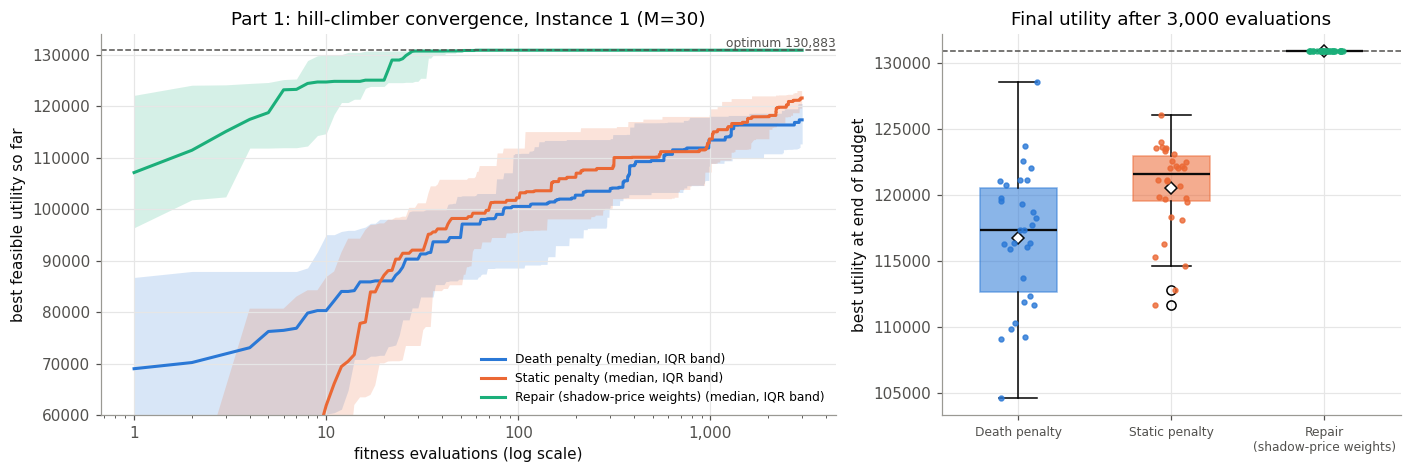

Repair HC: evaluations needed to reach the optimum  min=8  median=56  max=120
Repair vs Death penalty  : Mann-Whitney U=900, p=6.04e-13, A12=1.00 (large)
Repair vs Static penalty : Mann-Whitney U=900, p=6.05e-13, A12=1.00 (large)


In [13]:
# Convergence curves (left) and final results of all 30 runs (right)
cols3 = [C["blue"], C["orange"], C["aqua"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
plot_convergence(axes[0], p1_tr, cols3, I1.optimum, "Part 1: hill-climber convergence, Instance 1 (M=30)",
                 ylim=(60_000, 134_000))
plot_box(axes[1], {k: p1_df.loc[p1_df.variant == k, "best_utility"].values for k in p1_handlers},
         cols3, "Final utility after 3,000 evaluations", optimum=I1.optimum)
plt.tight_layout(); plt.show()

# How quickly does repair reach the optimum, and is it significantly better than the penalty versions?
rep = p1_df[p1_df.variant == "Repair (shadow-price weights)"]
print("Repair HC: evaluations needed to reach the optimum  "
      f"min={rep.evals_to_opt.min():.0f}  median={rep.evals_to_opt.median():.0f}  max={rep.evals_to_opt.max():.0f}")
for other in ("Death penalty", "Static penalty"):
    r = compare(rep.best_utility, p1_df.loc[p1_df.variant == other, "best_utility"], "greater")
    print(f"Repair vs {other:15s}: Mann-Whitney U={r['U']:.0f}, p={r['p']:.2e}, A12={r['A12']:.2f} ({r['effect']})")

**How to read the convergence plots** (the same format is used throughout): the line is the median best-so-far value over the 30 runs, the shaded band covers the middle half of the runs (25th to 75th percentile), and the dashed line is the true optimum. The horizontal axis (evaluations) is logarithmic (1, 10, 100, 1,000), so the whole run, from the fast early search to the long tail, fits in one plot. The vertical axis (utility) is zoomed in on values near the optimum so that the final differences are visible. That is why a line can enter the plot part-way along, before that point, its median utility is still below the visible range.

### P1.2 Discussion
* **Constraint handling matters more than the search moves.** With the same moves, acceptance rule and budget, the repair-based climber finds the true optimum (130,883) in **all 30 runs**, usually within a few dozen evaluations. The death-penalty and static-penalty climbers **never** reach it, and their results vary widely between runs (see table and boxplot). Both differences are significant (Mann–Whitney p ≪ 0.001, A12 = 1.0).
* **Why the penalty climbers fail.** About half of their moves produce an infeasible selection ("Feasible candidates (%)" column in the results table above), which is either rejected outright (death penalty) or heavily penalised (static penalty). Near the limits, the only moves left are removing a model or swapping two models with very similar resource use, so these climbers get stuck often. Restarts help, but 3,000 evaluations are not enough.
* **Why repair works.** Every repaired selection is feasible *and full*: the ADD step fills any spare capacity with the best-value models. This also makes each move bigger than it looks: when a flip adds model *j*, the repair drops the worst-value models to make room for it and then refills any space left over, so the whole selection is reorganised around model *j*. The `keep`/`ban` rule stops the repair from simply undoing the move.
* **Cost.** Repair costs extra computing time per evaluation (≈ 2.5× higher "Time per eval (µs)" in the table). On this instance that is not a major setback, since a whole run takes well under a second.

**Decision:** repair is used as the constraint-handling strategy for Part 2. Part 3 tests whether its advantage over a penalty also holds on the larger instance, and at what cost.

---
## Part 2: Advanced metaheuristic (Instance 2, n = 90, m = 5)

### P2.1 Algorithm choice: steady-state GA with greedy repair (after Chu & Beasley, 1998)
The Chu–Beasley GA is a well-known population method for the 0-1 multidimensional knapsack problem, tested on the standard OR-Library benchmarks for this problem type. I reimplemented its core ideas from scratch, with three implementation details of our own:
* **one repair interface for both algorithms**: the same repair code serves the hill climber (Part 1) and the GA;
* **duplicates never use the budget**: as in Chu & Beasley, children identical to a population member are discarded; here the check happens before the child is evaluated (using a hash set), so duplicates never count towards the evaluation budget;
* **a budgeted evaluator**, so every comparison uses exactly the same number of evaluations.

### P2.2 Why these operators
| Component | Choice | Why |
|---|---|---|
| Population model | steady-state, μ = 100, child replaces the worst member if at least as good | A new child can be a parent in the very next step, so good children are used faster than in a generational GA. Only the worst member is replaced, so the best is never lost (**elitism**) |
| Selection | binary tournament (k = 2) | Mild, constant selection pressure that balances exploration and exploitation. It only asks which of two is better, so it does not depend on the size of the fitness values; roulette-wheel selection would be nearly random here (all utilities ≈ 11,000) |
| Crossover | **uniform** | The order of the models means nothing, so one- and two-point crossover would only bias inheritance towards models with nearby index numbers. Uniform crossover (Syswerda, 1989) has no such bias: models both parents share are kept, the rest is a 50/50 choice |
| Mutation | bit-flip, pₘ = 1/n (about 1 flip per child) | Adds variation to help escape local optima while keeping most of what the child inherited; the repair then rebalances the child |
| Constraint handling | **greedy DROP/ADD repair with shadow-price weights** | Part 1 showed repair beats the penalty approaches: every evaluated child is feasible and full. The shadow prices (§0.2) show only resource 2 is scarce, so the ratio $p_j / \lambda_2 r_{2j}$ ranks models by utility per unit of the resource that actually runs out |
| Diversity | duplicate rejection | Stops the population filling up with copies of the best selection, a known risk when every child is repaired |

**Cost per child:** crossover and mutation take time proportional to n (the number of models). Repair and evaluation take time proportional to n × m (models × resources). The ratio order used by the repair is computed only once per run.

In [14]:
P2_BUDGET = 5_000
p2_ga, p2_ga_tr, p2_div = run_many(steady_state_ga, I2, dual_repair, P2_BUDGET, label="Steady-state GA + shadow-price repair")
summarise(p2_ga)

,Mean,Std dev,Median,Best,Worst,Mean gap (%),Success (%),Median evals to optimum,Feasible candidates (%),Time per run (s),Time per eval (µs),Duplicates skipped per run
Variant,,,,,,,,,,,,
Steady-state GA + shadow-price repair,"11,191.0",0.0,"11,191.0","11,191.0","11,191.0",0.00,100,340,100.0,4.00,800,"16,450"


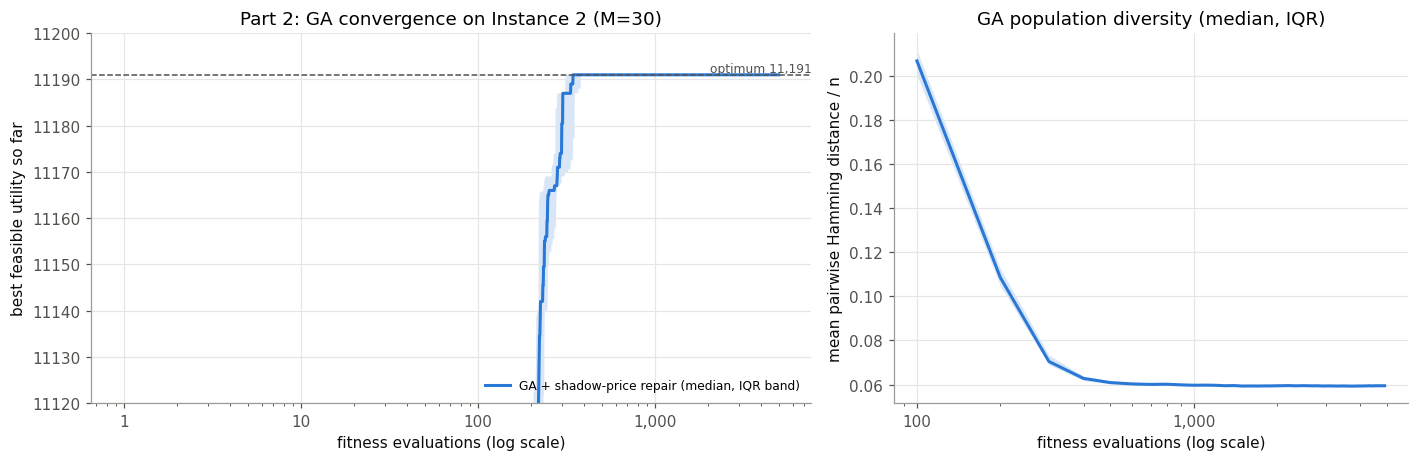

In [15]:
# Convergence (left) and population diversity (right) over the 30 runs
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
plot_convergence(axes[0], {"GA + shadow-price repair": p2_ga_tr}, [C["blue"]], I2.optimum,
                 "Part 2: GA convergence on Instance 2 (M=30)", ylim=(11_120, 11_200))
D = np.array([d[:min(map(len, p2_div))] for d in p2_div])       # diversity logs, cut to equal length
xs = 100 * np.arange(1, D.shape[1] + 1)                          # logged every 100 evaluations
axes[1].fill_between(xs, *np.percentile(D, [25, 75], axis=0), color=C["blue"], alpha=0.18, lw=0)
axes[1].plot(xs, np.median(D, 0), color=C["blue"])
axes[1].set(xscale="log", xlabel="fitness evaluations (log scale)", ylabel="mean pairwise Hamming distance / n",
            title="GA population diversity (median, IQR)")
plain_log_axis(axes[1])
plt.tight_layout(); plt.show()

In [16]:
# Recover the best GA selection (re-running its seed gives exactly the same run) and check its resource use
best = p2_ga.loc[p2_ga.best_utility.idxmax()]
rng = np.random.default_rng(MASTER_SEED + int(best.run))
_, ev_best, _ = steady_state_ga(I2, dual_repair(I2), P2_BUDGET, rng)
x_best = ev_best.best_x
print(f"Best GA solution (run {int(best.run)}): utility = {I2.p @ x_best:,.0f}  "
      f"(optimum {I2.optimum:,.0f}), {x_best.sum()} of 90 models deployed")
print("deployed model indices:", np.flatnonzero(x_best).tolist())
pd.DataFrame({"Resource": [f"R{i+1}" for i in range(I2.m)], "Used": (I2.R @ x_best).astype(int),
              "Capacity": I2.b.astype(int), "Utilisation (%)": np.round(100 * (I2.R @ x_best) / I2.b, 1),
              "Shadow price": np.round(I2.duals, 3), "Within capacity": (I2.R @ x_best) <= I2.b}).set_index("Resource")

Best GA solution (run 0): utility = 11,191  (optimum 11,191), 51 of 90 models deployed
deployed model indices: [0, 4, 6, 8, 9, 10, 11, 12, 15, 17, 18, 21, 22, 25, 29, 30, 33, 34, 38, 39, 41, 42, 47, 48, 49, 50, 51, 53, 55, 57, 58, 59, 60, 61, 62, 63, 65, 66, 68, 69, 72, 73, 75, 77, 81, 82, 84, 85, 86, 87, 89]


,Used,Capacity,Utilisation (%),Shadow price,Within capacity
Resource,,,,,
R1,1777,2100,84.6,0.00,True
R2,1100,1100,100.0,2.77,True
R3,2259,3300,68.5,0.00,True
R4,2232,3700,60.3,0.00,True
R5,2418,3600,67.2,0.00,True


### P2.3 Discussion
* **Quality:** the GA reaches the **true optimum (11,191) in 30/30 runs**, after a median of a few hundred evaluations. Even the full budget of 5,000 evaluations is just a tiny fraction (about 10⁻²⁴) of all 2⁹⁰ possible selections.
* **Validity:** the audit table above checks the best selection independently. Resource 2 is used to exactly 100 %, as the shadow prices predicted, and every other resource has spare capacity.
* **Diversity:** starts high (random repaired selections), drops as selection takes effect, and levels off above zero. Duplicate rejection stops it from collapsing completely, so the GA keeps exploring after it has found the optimum.
* **Hidden cost of duplicate rejection.** Repair turns many different children into the *same* full selection. Once the population has converged, most children are duplicates and are thrown away without using budget ("Duplicates skipped per run" column). Each one still costs a crossover, a mutation and a repair, so computing time per evaluation grows after convergence. Part 3 measures this cost against a penalty-based GA.

Whether the GA is actually needed here, or whether the Part 1 hill climber would do just as well, is examined in §4.2.

---
## Part 3: Empirical study and hypothesis testing (Instance 2)

### P3.1 Research question and hypothesis
Part 1 showed that repair beats penalties on the small instance. Here we test whether that also holds for the bigger Instance 2, using the GA, and at what cost. The two variants differ **only** in how they handle constraints:
* **Variant A, repair:** every child is repaired with the shadow-price repair (the Part 2 GA).
* **Variant B, static penalty:** children are not repaired. Infeasible children get the static penalty from §1.1.

**Null hypothesis H0.** *Both variants have the same distribution of final utility.*

**Hypothesis H1 (one-sided).** *The repair GA reaches a higher final utility than the penalty GA under the same evaluation budget.*

**Why we expect this.** The optimum sits exactly on the limit of resource 2 (100 % used). Near that limit, crossover and mutation often produce infeasible children, in both GAs. The penalty GA evaluates these children as they are, so part of its budget goes on selections that can never count as a solution. The repair GA fixes every child before it is evaluated, turning it into a full, feasible selection.

### P3.2 Protocol
* **Equal budget:** 5,000 fitness evaluations per run, counted by the shared `Evaluator`, so neither variant can evaluate more.
* **M = 30 independent runs per variant.** Run *k* of each variant uses seed 42 + k. The two variants make different random choices from the first step onwards, so the two sets of runs are treated as **independent samples**.
* **Only the constraint handling changes.** Everything else stays fixed: steady-state GA, μ = 100, binary tournament, uniform crossover, pₘ = 1/n, duplicate rejection.
* **Statistics:** one-sided **Mann–Whitney U** test at α = 0.05. It is non-parametric, so it does not assume normally distributed results, which matters here because many runs end exactly at the optimum. The Wilcoxon signed-rank test is meant for paired samples; our runs are independent, so the Mann–Whitney U test is the appropriate choice. It is reported with the **Vargha–Delaney A12** effect size (Vargha & Delaney, 2000) (the chance that a random run of one variant beats a random run of the other), as recommended for randomised algorithms by Arcuri & Briand (2011).

In [17]:
P3_BUDGET = 5_000
# Variant A is exactly the Part 2 GA (same settings, seeds and budget), so its 30 runs are reused
A_rep, A_rep_tr = p2_ga.assign(variant="Repair (shadow-price weights)"), p2_ga_tr
A_pen, A_pen_tr, _ = run_many(steady_state_ga, I2, StaticPenalty, P3_BUDGET, label="Static penalty")
A_df = pd.concat([A_rep, A_pen], ignore_index=True)
summarise(A_df)

,Mean,Std dev,Median,Best,Worst,Mean gap (%),Success (%),Median evals to optimum,Feasible candidates (%),Time per run (s),Time per eval (µs),Duplicates skipped per run
Variant,,,,,,,,,,,,
Repair (shadow-price weights),"11,191.0",0.0,"11,191.0","11,191.0","11,191.0",0.00,100,340,100.0,4.00,800,"16,450"
Static penalty,"11,155.5",22.1,"11,157.0","11,187.0","11,112.0",0.32,0,never,58.7,0.52,104,196


### P3.3 Results under an equal evaluation budget

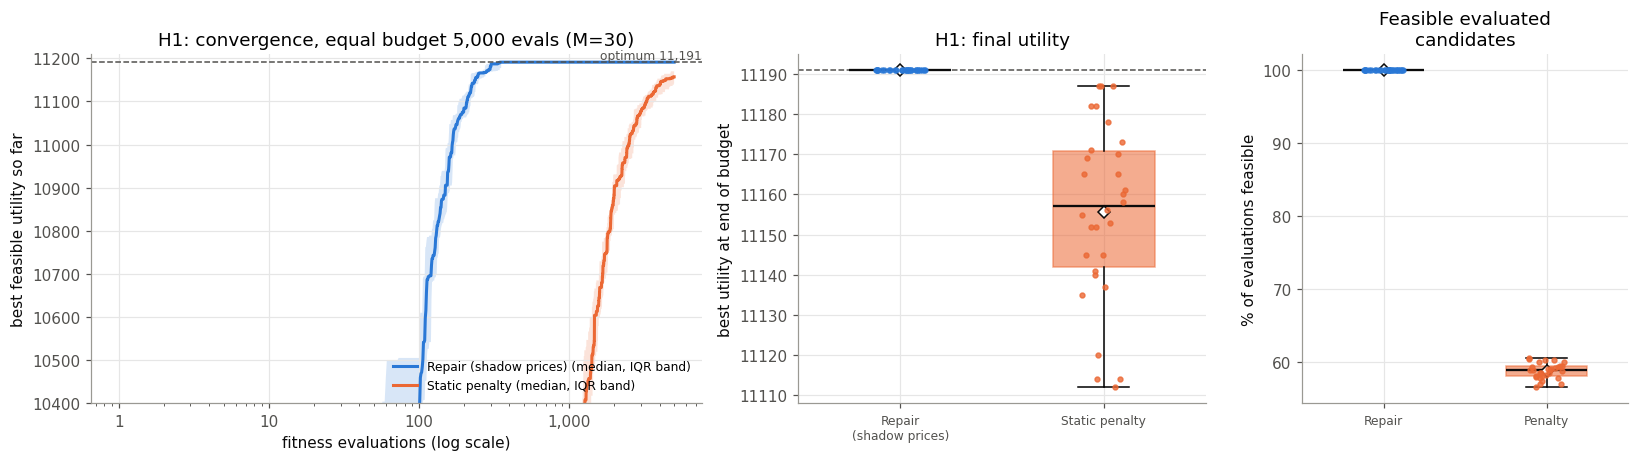

H1  Repair vs Penalty: median 11,191 vs 11,157;  U=900, p=6.01e-13, A12=1.00 (large)  ->  reject H0 at alpha=0.05
CPU cost per evaluation: repair 800 µs, penalty 104 µs  ->  ratio 7.7x


In [18]:
# Convergence (left), final utility (middle), share of evaluated candidates that were feasible (right)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.5, 1, 0.8]})
plot_convergence(axes[0], {"Repair (shadow prices)": A_rep_tr, "Static penalty": A_pen_tr},
                 [C["blue"], C["orange"]], I2.optimum, "H1: convergence, equal budget 5,000 evals (M=30)",
                 ylim=(10_400, 11_210))
plot_box(axes[1], {"Repair (shadow prices)": A_rep.best_utility.values, "Static penalty": A_pen.best_utility.values},
         [C["blue"], C["orange"]], "H1: final utility", optimum=I2.optimum)
plot_box(axes[2], {"Repair": 100 * A_rep.feasible_rate.values, "Penalty": 100 * A_pen.feasible_rate.values},
         [C["blue"], C["orange"]], "Feasible evaluated\ncandidates", ylabel="% of evaluations feasible")
plt.tight_layout(); plt.show()

# Hypothesis test for H1, and the computing cost per evaluation of each variant
rA = compare(A_rep.best_utility, A_pen.best_utility, "greater")
print(f"H1  Repair vs Penalty: median {rA['median A']:,.0f} vs {rA['median B']:,.0f};  U={rA['U']:.0f}, "
      f"p={rA['p']:.2e}, A12={rA['A12']:.2f} ({rA['effect']})  ->  "
      f"{'reject H0' if rA['p'] < 0.05 else 'cannot reject H0'} at alpha=0.05")
t_rep = A_rep.time_s.sum() / A_rep.evals_used.sum(); t_pen = A_pen.time_s.sum() / A_pen.evals_used.sum()
print(f"CPU cost per evaluation: repair {1e6*t_rep:.0f} µs, penalty {1e6*t_pen:.0f} µs  ->  ratio {t_rep/t_pen:.1f}x")

**H1 is supported.** With the same budget of 5,000 evaluations, the repair GA reaches the optimum in every run. The penalty GA never reaches it, and ends lower and with more spread. The difference is large and highly significant (A12 = 1.0). The right-hand panel shows why: 41.3 % of the penalty GA's evaluations are spent on infeasible children, which can never count as a solution and only influence selection. Every repair evaluation is a feasible, full selection.

### P3.4 Equal computing time
Equal evaluation budgets are the standard way to compare fairly, but repair does extra work inside `prepare()` (and on duplicate children that are discarded) which the evaluation count does not show. The measured time per evaluation does include it: on the development machine, a repair evaluation took 7.5× as long as a penalty evaluation (the cell above prints the ratio on the current machine). To check whether H1 only holds because we count evaluations rather than time, the penalty GA is run again with **37,500 evaluations** (5,000 × 7.5), which gives it roughly the **same total computing time** as the repair GA. A fixed budget, rather than a time limit, keeps the result reproducible on any machine.

In [19]:
EQ_TIME_BUDGET = 37_500
A_pen_eq, A_pen_eq_tr, _ = run_many(steady_state_ga, I2, StaticPenalty, EQ_TIME_BUDGET, label="Static penalty, 37.5k evals (≈ equal time)")
display(summarise(pd.concat([A_rep, A_pen_eq], ignore_index=True)))
rA2 = compare(A_rep.best_utility, A_pen_eq.best_utility, "greater")
print(f"Repair(5k) vs Penalty(37.5k): p={rA2['p']:.2e}, A12={rA2['A12']:.2f} ({rA2['effect']})")

,Mean,Std dev,Median,Best,Worst,Mean gap (%),Success (%),Median evals to optimum,Feasible candidates (%),Time per run (s),Time per eval (µs),Duplicates skipped per run
Variant,,,,,,,,,,,,
Repair (shadow-price weights),"11,191.0",0.0,"11,191.0","11,191.0","11,191.0",0.00,100,340,100.0,4.00,800,"16,450"
"Static penalty, 37.5k evals (≈ equal time)","11,190.9",0.7,"11,191.0","11,191.0","11,187.0",0.00,97,"10,124",46.9,3.98,106,"3,032"


Repair(5k) vs Penalty(37.5k): p=1.67e-01, A12=0.52 (negligible)


**With equal computing time, H1 is not supported.** Given 37,500 evaluations (about the same total time, see the "Time per run (s)" column), the penalty GA reaches the optimum in 29/30 runs, and the difference from repair is no longer significant (p ≈ 0.17, A12 ≈ 0.52, negligible).

### P3.5 Discussion: quality, constraint enforcement and time
The advantage of repair is that it gets more out of **each evaluation**. It needs far fewer evaluations to reach the optimum, but each one costs more computing time. Whether needing fewer evaluations or having cheaper evaluations matters more depends on what one evaluation costs. If evaluations were expensive, repair would clearly be the better choice. For example, if each model selection had to be deployed and tested on real hardware, even one second per evaluation would be far more than the repair's extra work of under 1 ms, making it negligible. With a cheap objective like this one (about 0.1 ms per evaluation), the repair's extra work is large by comparison, and a penalty GA given enough time gets there too.

Two details keep this conclusion fair to repair:
* **Most of the 7.5× extra time comes from duplicates, not from the repair itself.** After it has found the optimum (median 340 evaluations), the repair GA keeps producing children that the repair turns back into existing population members, and 16,450 are discarded per run ("Duplicates skipped per run" column). In the Part 1 hill climber, which has no duplicate check, repair costs only ≈ 2.5× a plain evaluation. Stopping once the population has converged, or mutating duplicates more strongly, would remove most of this overhead.
* **Repair still reaches the optimum sooner in real time.** A typical repair run finds the optimum after a median of 340 evaluations, which takes at most about 0.3 seconds. The penalty GA needs a median of 10,124 evaluations, roughly 1 second (calculated from the "Time per eval (µs)" column above).

| | Repair (shadow prices) | Static penalty |
|---|---|---|
| Solution quality | optimum in 30/30 runs (5k evals) | optimum in 0/30 runs at 5k evals, 29/30 at 37.5k (≈ equal time) |
| Evaluations to reach the optimum (median) | 340 | never within 5k evals; 10,124 with 37.5k (about 30× more) |
| Time to reach the optimum | at most about 0.3 s | roughly 1 s |
| Constraint enforcement | 100 % of evaluated candidates feasible, guaranteed by the repair | 41.3 % (for 5k) and 53.1 % (for 37.5k) of evaluations infeasible (100 % minus "Feasible candidates (%)"). Final feasibility depends on choosing the penalty weight λ well |
| Computing time per evaluation | high (≈ 7.5× the penalty GA) | low: one matrix–vector product |
| What must be set up | a ranking of the models for the repair (shadow prices, §0.2) | only one number, the penalty weight λ |
| What can go wrong | with less suitable ranking weights (e.g. capacity-normalised), it needs about twice as many evaluations (§4.1) | λ too small → infeasible selections score best; λ too large → the search avoids the limit and misses the optimum |

---
## 4. Additional experiments
The main results raise two follow-up questions, answered here with the same protocol (30 runs, equal budgets, Mann–Whitney U + A12):
* **§4.1 Which repair weights work best?** The repair is the most problem-specific part of the design. Do the shadow prices actually matter, or would a simpler weighting do?
* **§4.2 Does the population help?** The GA solved Instance 2 easily. Would the Part 1 hill climber have done just as well, and if so, when is the GA worth it?

### 4.1 Which repair weights work best?
The repair ranks models by value for money, utility ÷ weighted resource use, and the weights decide which resources count. We compare:
* **Shadow-price weights** (used so far): $p_j/\sum_i \lambda_i r_{ij}$. Only scarce resources count; on Instance 2 that is resource 2 alone.
* **Capacity-normalised weights:** $p_j/\sum_i r_{ij}/b_i$. Each resource counts as a fraction of its capacity, and all five count equally. This is the usual default, also used in the module's lab notebook.

**Null hypothesis H0.** *Both repair variants have the same distribution of results.*

**Hypothesis H2 (one-sided).** *Shadow-price repair reaches the optimum in fewer evaluations than capacity-normalised repair.*

**Why we expect this.** The capacity-normalised ratio also counts the four resources that are **not** scarce. A model that uses little of resource 2 but a lot of the others then looks expensive and is dropped first, even though removing it frees almost none of the resource that is actually short.

**What we measure.** The number of evaluations each run needs to reach the true optimum (fewer is better). A run that never reaches it is counted as budget + 1, which keeps it ranked last.

In [20]:
# Why should the weights matter? Compare the two rankings, and each repair's greedy result on its own.
Hd, Hn = dual_repair(I2), naive_repair(I2)
rho = spearmanr(Hd.ratio, Hn.ratio).statistic        # 1.0 = identical ranking of the 90 models
g_d = I2.p @ Hd.prepare(np.zeros(I2.n, np.int8)); g_n = I2.p @ Hn.prepare(np.zeros(I2.n, np.int8))
print(f"Spearman rank correlation of the two value-to-weight rankings: rho = {rho:.2f}")
print(f"Pure greedy (ADD from empty), no search: shadow-price = {g_d:,.0f} (gap {100*(I2.optimum-g_d)/I2.optimum:.2f} %), "
      f"normalised = {g_n:,.0f} (gap {100*(I2.optimum-g_n)/I2.optimum:.2f} %)")

# The shadow-price variant is the Part 2 GA (A_rep); only the capacity-normalised variant needs new runs
B_nai, B_nai_tr, _ = run_many(steady_state_ga, I2, naive_repair, P3_BUDGET, label="Repair (capacity-normalised weights)")
B_df = pd.concat([A_rep, B_nai], ignore_index=True)
summarise(B_df)

Spearman rank correlation of the two value-to-weight rankings: rho = 0.84
Pure greedy (ADD from empty), no search: shadow-price = 11,167 (gap 0.21 %), normalised = 10,819 (gap 3.32 %)


,Mean,Std dev,Median,Best,Worst,Mean gap (%),Success (%),Median evals to optimum,Feasible candidates (%),Time per run (s),Time per eval (µs),Duplicates skipped per run
Variant,,,,,,,,,,,,
Repair (shadow-price weights),"11,191.0",0.0,"11,191.0","11,191.0","11,191.0",0.00,100,340,100.0,4.00,800,"16,450"
Repair (capacity-normalised weights),"11,191.0",0.0,"11,191.0","11,191.0","11,191.0",0.00,100,659,100.0,2.19,439,"5,785"


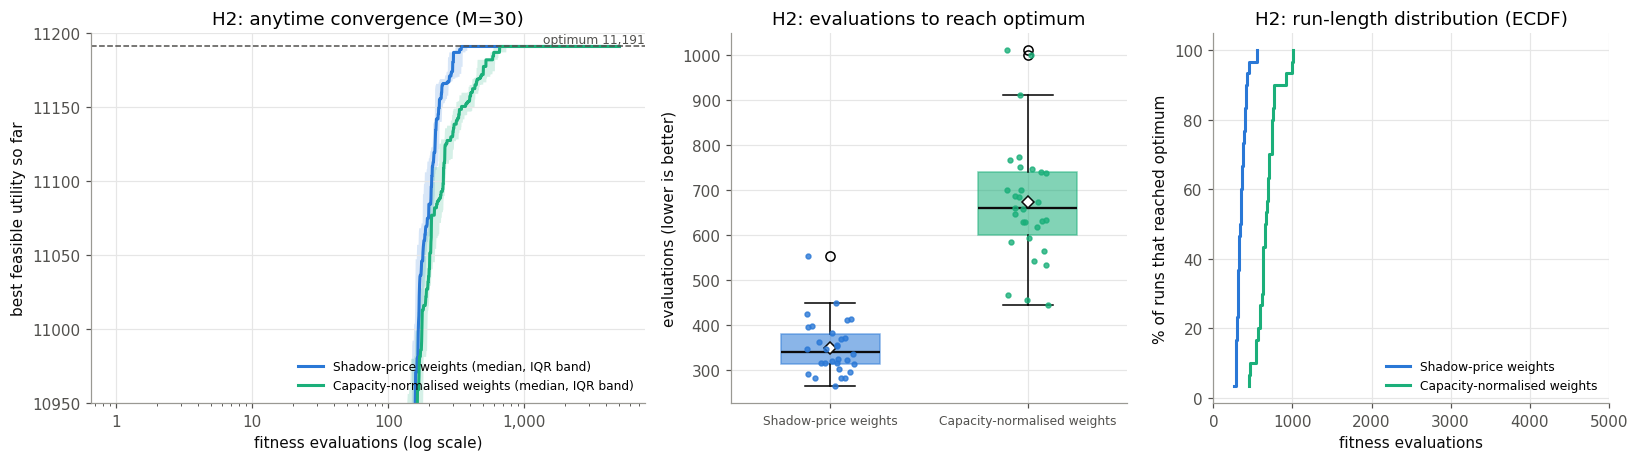

H2  evaluations to optimum, shadow-price vs normalised: median 340 vs 659;  U=6, p=2.74e-11, A12=0.01 (large)  ->  reject H0 at alpha=0.05


In [21]:
# Convergence (left), evaluations to optimum (middle), share of runs that reached the optimum over time (right)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.4, 1, 1]})
plot_convergence(axes[0], {"Shadow-price weights": A_rep_tr, "Capacity-normalised weights": B_nai_tr},
                 [C["blue"], C["aqua"]], I2.optimum, "H2: anytime convergence (M=30)", ylim=(10_950, 11_200))
rl = {"Shadow-price weights": A_rep.evals_to_opt.fillna(P3_BUDGET + 1).values,
      "Capacity-normalised weights": B_nai.evals_to_opt.fillna(P3_BUDGET + 1).values}
plot_box(axes[1], rl, [C["blue"], C["aqua"]], "H2: evaluations to reach optimum", ylabel="evaluations (lower is better)")
for (k, v), col in zip(rl.items(), [C["blue"], C["aqua"]]):      # cumulative % of runs that have found the optimum
    s = np.sort(v); axes[2].step(s, np.arange(1, s.size + 1) / s.size * 100, where="post", color=col, label=k)
axes[2].set(xlabel="fitness evaluations", ylabel="% of runs that reached optimum",
            title="H2: run-length distribution (ECDF)", xlim=(0, P3_BUDGET)); axes[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

# Test H2: fewer evaluations to reach the optimum is better, so the one-sided alternative is "less"
# (A12 below 0.5 here means the shadow-price repair tends to need fewer evaluations)
rB = compare(rl["Shadow-price weights"], rl["Capacity-normalised weights"], "less")
print(f"H2  evaluations to optimum, shadow-price vs normalised: median {rB['median A']:.0f} vs {rB['median B']:.0f};  "
      f"U={rB['U']:.0f}, p={rB['p']:.2e}, A12={rB['A12']:.2f} ({rB['effect']})  ->  "
      f"{'reject H0' if rB['p'] < 0.05 else 'cannot reject H0'} at alpha=0.05")

**H2 is supported.** Both repairs reach the optimum eventually, because the GA can make up for a weaker repair given enough evaluations. But the shadow-price repair gets there in significantly fewer evaluations: a median of 340 against 659, roughly half as many, a large effect (A12 = 0.01, i.e. the shadow-price run needs fewer evaluations in almost every pairing). The convergence plot shows the same: the shadow-price repair is ahead early on, and both have caught up by about 1,000 evaluations.

**Why it happens.** The two rankings are similar but not identical (Spearman ρ = 0.84), and the models they disagree on are exactly the ones that decide the optimum. The shadow-price greedy alone, with no search at all, already gets within 0.21 % of the optimum, while the normalised greedy is 3.32 % away. A better ranking gives a better starting population *and* a better repair of every child. (The normalised repair actually uses *less* computing time per evaluation, because it converges later and so produces fewer duplicates.)

**Takeaway:** the repair is where knowledge about the problem enters the GA, and shadow prices are a cheap, well-founded way to provide it. The difference shows in *how fast* the optimum is found rather than *whether* it is found, which is why evaluations-to-optimum is reported alongside final quality.

### 4.2 Does the population help?
**Question.** In Part 2 the GA solved Instance 2 in every run. Would the simpler Part 1 hill climber, given the same repair and the same 5,000 evaluations, have done just as well? And if so, is there a setting where the GA's population makes a real difference?

**Approach.** First, the hill climber with shadow-price repair is run on Instance 2 and compared with the Part 2 GA. Then both are run on a **harder instance** (30 runs, 3,000 evaluations each): Instance 2 with all capacities multiplied by 0.3 (*Instance 2-T*). Its shadow prices show **two** scarce resources (R1 and R2), so no single ratio ranks the models perfectly and the repair helps less. The exact optimum is again computed for scoring only.

In [22]:
# Step 1: hill climber vs GA on the original Instance 2 (the GA runs are reused from Part 2)
p2_hc, p2_hc_tr, _ = run_many(hill_climber, I2, dual_repair, P2_BUDGET, label="Hill climber + shadow-price repair")
display(summarise(pd.concat([p2_ga, p2_hc], ignore_index=True)))
# runs that never reach the optimum count as budget + 1
r = compare(p2_ga.evals_to_opt.fillna(P2_BUDGET + 1), p2_hc.evals_to_opt.fillna(P2_BUDGET + 1), "two-sided")
print(f"Evaluations to optimum, GA vs HC: median {r['median A']:.0f} vs {r['median B']:.0f}, "
      f"two-sided Mann-Whitney p={r['p']:.2f}, A12={r['A12']:.2f} ({r['effect']})")

,Mean,Std dev,Median,Best,Worst,Mean gap (%),Success (%),Median evals to optimum,Feasible candidates (%),Time per run (s),Time per eval (µs),Duplicates skipped per run
Variant,,,,,,,,,,,,
Steady-state GA + shadow-price repair,"11,191.0",0.0,"11,191.0","11,191.0","11,191.0",0.00,100,340,100.0,4.00,800,"16,450"
Hill climber + shadow-price repair,"11,191.0",0.0,"11,191.0","11,191.0","11,191.0",0.00,100,294,100.0,0.88,176,nan


Evaluations to optimum, GA vs HC: median 340 vs 294, two-sided Mann-Whitney p=0.40, A12=0.56 (small)


In [23]:
import copy
# Step 2: build Instance 2-T (same models, every capacity cut to 30 %), then run both algorithms on it
I2T = copy.deepcopy(I2)
I2T.name, I2T.b = "Instance 2-T (capacities x 0.3)", np.floor(0.3 * I2.b)
solve_reference(I2T); compute_shadow_prices(I2T)
print(f"{I2T.name}: b = {I2T.b.astype(int)}, optimum = {I2T.optimum:,.0f}, shadow prices = {np.round(I2T.duals, 2)}")

STRESS_BUDGET = 3_000
stress = {}
for tag, I, H in [("Instance 2-T (two scarce resources)", I2T, dual_repair)]:
    ga_df, ga_tr, _ = run_many(steady_state_ga, I, H, STRESS_BUDGET, label="GA")
    hc_df, hc_tr, _ = run_many(hill_climber, I, H, STRESS_BUDGET, label="HC")
    stress[tag] = (I, ga_df, ga_tr, hc_df, hc_tr)
    s = summarise(pd.concat([ga_df, hc_df]))[["Mean", "Std dev", "Worst", "Success (%)", "Median evals to optimum", "Time per run (s)"]]
    r = compare(ga_df.best_utility, hc_df.best_utility, "greater")    # is the GA's final utility higher?
    print(f"\n{tag}:  GA > HC one-sided Mann-Whitney p={r['p']:.2e}, A12={r['A12']:.2f} ({r['effect']})")
    display(s)

Instance 2-T (capacities x 0.3): b = [ 630  330  990 1110 1080], optimum = 7,168, shadow prices = [2.67 4.93 0.   0.   0.  ]



Instance 2-T (two scarce resources):  GA > HC one-sided Mann-Whitney p=2.59e-07, A12=0.80 (large)


,Mean,Std dev,Worst,Success (%),Median evals to optimum,Time per run (s)
Variant,,,,,,
GA,"7,168.0",0.0,"7,168.0",100,171,2.82
HC,"7,154.8",11.0,"7,146.0",40,"1,505",0.77


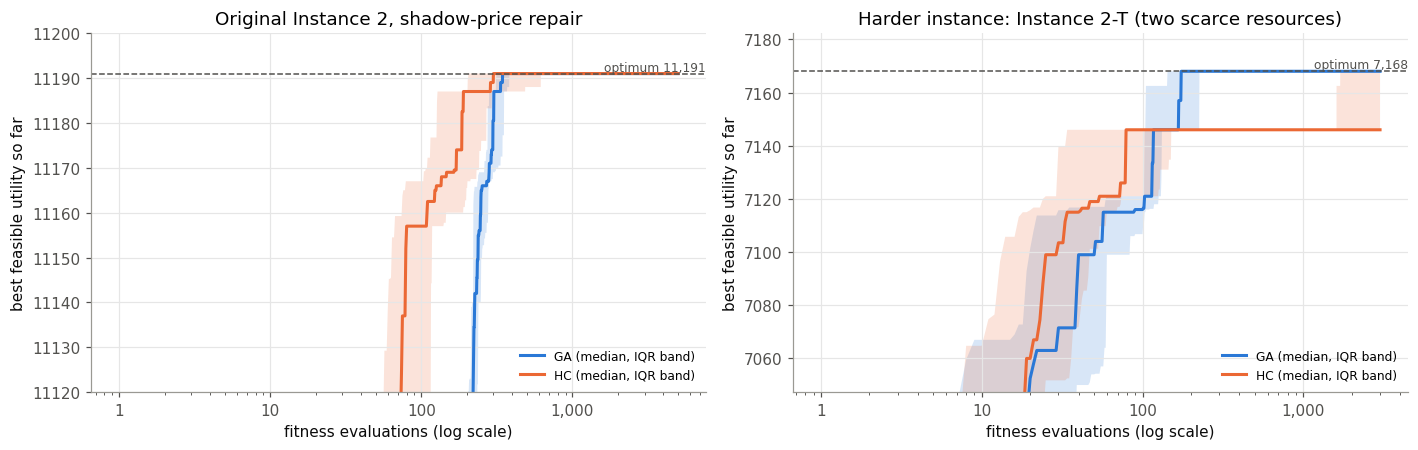

In [24]:
# Convergence: original instance (left), harder Instance 2-T (right)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
plot_convergence(axes[0], {"GA": p2_ga_tr, "HC": p2_hc_tr}, [C["blue"], C["orange"]], I2.optimum,
                 "Original Instance 2, shadow-price repair", ylim=(11_120, 11_200))
for ax, (tag, (I, ga_df, ga_tr, hc_df, hc_tr)) in zip(axes[1:], stress.items()):
    lo = np.percentile(np.concatenate([ga_tr[:, 50], hc_tr[:, 50]]), 10)    # y-axis starts near early values
    plot_convergence(ax, {"GA": ga_tr, "HC": hc_tr}, [C["blue"], C["orange"]], I.optimum,
                     f"Harder instance: {tag}", ylim=(lo, I.optimum + 0.002 * I.optimum))
plt.tight_layout(); plt.show()

**On the original instance, no.** The hill climber also reaches the optimum in 30/30 runs, and there is no significant difference in how many evaluations each needs (two-sided test above). With only one scarce resource and a near-perfect repair order (§4.1: the shadow-price greedy alone gets within 0.21 % of the optimum), the repair does most of the work, and a good local search is enough.

**On the harder instance, yes.** The GA reaches the optimum in 30/30 runs, the hill climber in only 12/30, a large and significant difference (see output). With two scarce resources, improving a selection often means exchanging several models at once to keep both resources within limits. Uniform crossover followed by repair makes such multi-model changes naturally, by combining models that *different* population members got right. The hill climber changes only one or two models at a time, so it gets stuck more often.

**Takeaway:** the GA is the more robust choice. On the original instance its advantage is hidden by a very good repair, but it shows as soon as the problem gets harder.

---
## 5. Conclusions and limitations
1. **Part 1:** on Instance 1, the constraint handling decided the outcome. With the same moves and budget, a move-preserving greedy repair turned a weak hill climber (penalty versions: optimum never found) into one that finds the true optimum in 30/30 runs.
2. **Part 2:** a steady-state GA built from scratch, with shadow-price repair (prices computed by our own Lagrangian routine), uniform crossover and duplicate rejection, finds the true optimum of Instance 2 in 30/30 runs.
3. **Part 3:** H1 is supported with equal *evaluation* budgets (A12 = 1.0), but **not** with roughly equal computing time, where a well-chosen static penalty catches up (29/30 optimal). The repair GA still reaches the optimum about 4× sooner in real time, and most of its extra cost comes from avoidable duplicates.
4. **Additional experiments:** shadow-price weights make the repair about twice as efficient as capacity-normalised weights (H2, large effect). The GA and the hill climber perform equally on the original instance, but on a harder instance with two scarce resources the GA reaches the optimum in every run, while the climber manages only 12/30.

**Limitations.**
* *Generalisation:* there is only one challenge instance, and it has a single scarce resource. On instances where several resources are scarce, the shadow prices spread across resources and the H2 advantage should shrink. Testing that would need more instances with tighter constraints (e.g. the OR-Library *mknapcb* set).
* *What the evaluation count measures:* it ignores the cost of repair, which is why §P3.4 adds a computing-time check. Absolute times depend on the machine; the relative ranking is what matters.
* *Settings:* the penalty weight λ was chosen by a rule rather than tuned. An adaptive penalty (Hadj-Alouane & Bean, 1997) was tried during development but never kicked in, because the best member stayed feasible. Uniform crossover, pₘ = 1/n and μ = 100 were not tuned separately for each variant. Both variants share them, so the comparison is fair, but other settings could change the effect sizes.
* *Statistics:* 30 runs per variant, non-parametric tests and effect sizes.

## 6. References
* Arcuri, A. & Briand, L. (2011). A practical guide for using statistical tests to assess randomized algorithms in software engineering. *Proc. ICSE 2011*, 1–10.
* Chu, P. C. & Beasley, J. E. (1998). A genetic algorithm for the multidimensional knapsack problem. *Journal of Heuristics*, 4(1), 63–86.
* Coello Coello, C. A. (2002). Theoretical and numerical constraint-handling techniques used with evolutionary algorithms: a survey of the state of the art. *Computer Methods in Applied Mechanics and Engineering*, 191(11–12), 1245–1287.
* Fisher, M. L. (1981). The Lagrangian relaxation method for solving integer programming problems. *Management Science*, 27(1), 1–18.
* Hadj-Alouane, A. B. & Bean, J. C. (1997). A genetic algorithm for the multiple-choice integer program. *Operations Research*, 45(1), 92–101.
* Held, M., Wolfe, P. & Crowder, H. P. (1974). Validation of subgradient optimization. *Mathematical Programming*, 6(1), 62–88.
* Olsen, A. L. (1994). Penalty functions and the knapsack problem. *Proc. 1st IEEE Conference on Evolutionary Computation*, 554–558.
* Pirkul, H. (1987). A heuristic solution procedure for the multiconstraint zero-one knapsack problem. *Naval Research Logistics*, 34(2), 161–172.
* Syswerda, G. (1989). Uniform crossover in genetic algorithms. *Proc. 3rd International Conference on Genetic Algorithms*, 2–9.
* Vargha, A. & Delaney, H. D. (2000). A critique and improvement of the CL common language effect size statistics of McGraw and Wong. *Journal of Educational and Behavioral Statistics*, 25(2), 101–132.